# 03 — Feature Engineering

Goal: create domain features with a documented business rationale, verify they are computable *before* churn happens (no leakage), and check that they actually add predictive value before adopting them.

Reusable logic: `src/features/engineering.py`. Preprocessing pipelines: `src/models/pipeline.py`.

In [1]:
import sys
from pathlib import Path

_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(p for p in _candidates if (p / "src").exists())
sys.path.insert(0, str(PROJECT_ROOT))
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data.clean import PROCESSED_DIR, clean_telco, load_raw
from src.features.engineering import add_features, save_features, ENGINEERED_FEATURES, ADDON_COLS

df = add_features(clean_telco(load_raw())[0])
df["churn_flag"] = (df["Churn"] == "Yes").astype(int)
pd.set_option("display.width", 140)


## 1. Engineered features and their rationale

| Feature | Rationale | Leakage risk |
|---|---|---|
| `tenure_band` | EDA shows churn concentrated in the first months; bins let linear models capture the non-linear tenure effect | None — tenure known at prediction time |
| `addon_count` | More add-on services = stickier bundle (EDA: churn falls with add-on count) | None |
| `has_addon_services` | Simple binary of the above for interpretable models | None |
| `service_breadth` | Total services owned (phone + internet + add-ons) | None |
| `avg_monthly_to_date` | `TotalCharges / tenure` = historical average effective monthly charge; captures pricing history | None; tenure=0 defined as 0.0 (no billing yet) |
| `auto_payment` | Automatic payments churn far less than electronic check in EDA | None |
| `fiber_no_protection` | Combines the two strongest churn signals: fiber optic without security/protection add-ons | None |

## 2. Build features and inspect them against churn

In [2]:
df[ENGINEERED_FEATURES].head()

,tenure_band,addon_count,has_addon_services,service_breadth,avg_monthly_to_date,auto_payment,fiber_no_protection
0,0-6 mo,1,1,2,29.85,0,0
1,25-48 mo,2,1,4,55.57,0,0
2,0-6 mo,2,1,4,54.08,0,0
3,25-48 mo,3,1,4,40.91,1,0
4,0-6 mo,0,0,2,75.82,0,1


             customers  churn_rate
tenure_band                       
0-6 mo            1481       0.529
13-24 mo          1024       0.287
25-48 mo          1594       0.204
49-72 mo          2239       0.095
7-12 mo            705       0.359


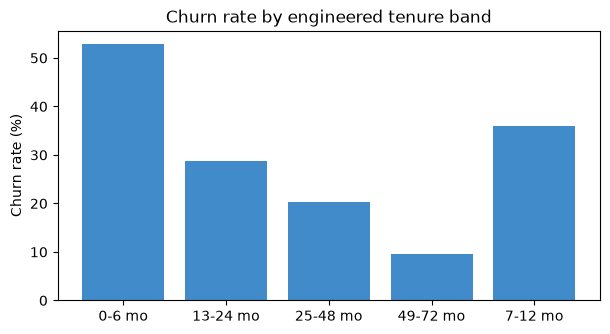

In [3]:
t = df.groupby('tenure_band', observed=True)['churn_flag'].agg(['count', 'mean']).rename(columns={'count': 'customers', 'mean': 'churn_rate'})
print(t.round(3))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(t.index, t['churn_rate'] * 100, color='#428bca')
ax.set(ylabel='Churn rate (%)', title='Churn rate by engineered tenure band')
savefig = ax.figure.savefig(PROJECT_ROOT / 'reports' / 'figures' / 'churn_by_tenure_band_feature.png', dpi=150, bbox_inches='tight')
plt.show()

In [4]:
t = df.groupby('addon_count')['churn_flag'].agg(['count', 'mean']).rename(columns={'count': 'customers', 'mean': 'churn_rate'})
print(t.round(3))

for col in ['has_addon_services', 'auto_payment', 'fiber_no_protection']:
    t = df.groupby(col)['churn_flag'].agg(['count', 'mean'])
    print(f'\n{col}:')
    print(t.round(3))

             customers  churn_rate
addon_count                       
0                 2219       0.214
1                  966       0.458
2                 1033       0.358
3                 1118       0.274
4                  852       0.223
5                  571       0.124
6                  284       0.053

has_addon_services:
                    count   mean
has_addon_services              
0                    2219  0.214
1                    4824  0.289

auto_payment:
              count   mean
auto_payment              
0              3977  0.347
1              3066  0.160

fiber_no_protection:
                     count   mean
fiber_no_protection              
0                     5668  0.195
1                     1375  0.554


In [5]:
print('avg_monthly_to_date by churn:')
print(df.groupby('Churn')['avg_monthly_to_date'].describe().round(2))
print('\ncorrelation with MonthlyCharges (collinearity check):')
print(df[['avg_monthly_to_date', 'MonthlyCharges', 'tenure']].corr().round(3))

avg_monthly_to_date by churn:
        count   mean    std    min    25%    50%    75%     max
Churn                                                          
No     5174.0  61.18  31.24   0.00  25.28  63.91  87.72  120.75
Yes    1869.0  74.43  24.96  14.15  57.98  79.31  93.93  121.40

correlation with MonthlyCharges (collinearity check):
                     avg_monthly_to_date  MonthlyCharges  tenure
avg_monthly_to_date                1.000           0.994   0.249
MonthlyCharges                     0.994           1.000   0.248
tenure                             0.249           0.248   1.000


## 3. Do the engineered features add predictive value?

Quick 5-fold CV on a 30% training subsample (the full, careful comparison happens in notebook 04). Same preprocessing pipelines as the final models; the only difference is the feature set. `customerID` and `Churn` are never features.

In [6]:
from sklearn.model_selection import train_test_split

from src.models.pipeline import FEATURE_SETS, build_pipeline
from src.models.evaluate import cv_scores

y = df['churn_flag']
X_all = df.drop(columns=['customerID', 'Churn', 'churn_flag'])

# A fixed stratified subsample keeps this sanity check fast; random_state fixed for reproducibility.
X_dev, _, y_dev, _ = train_test_split(X_all, y, train_size=0.3, stratify=y, random_state=42)

rows = []
for fs_name, (num_f, cat_f) in FEATURE_SETS.items():
    for model_name in ['logistic_regression', 'xgboost']:
        pipe = build_pipeline(model_name, num_f, cat_f)
        scores = cv_scores(pipe, X_dev[ num_f + cat_f], y_dev)
        rows.append({'feature_set': fs_name, 'model': model_name, **scores})
ablation = pd.DataFrame(rows)
print(ablation.round(4).to_string(index=False))

    feature_set               model  cv_test_accuracy  cv_test_precision  cv_test_recall  cv_test_f1  cv_test_roc_auc  cv_test_average_precision
           base logistic_regression            0.8026             0.6482          0.5607      0.6006           0.8475                     0.6655
           base             xgboost            0.7831             0.6043          0.5250      0.5590           0.8250                     0.6273
base+engineered logistic_regression            0.8135             0.6743          0.5732      0.6179           0.8494                     0.6646
base+engineered             xgboost            0.7831             0.6057          0.5161      0.5555           0.8272                     0.6248


## 4. Save the engineered dataset

In [7]:
out = save_features(df)
print('saved:', out)
print('shape:', df.shape)
print('new columns:', ENGINEERED_FEATURES)
print('missing values:', int(df.isna().sum().sum()))

saved: C:\Users\victus\Desktop\pre-wbl\telco-churn-analytics\data\processed\telco_features.csv
shape: (7043, 29)
new columns: ['tenure_band', 'addon_count', 'has_addon_services', 'service_breadth', 'avg_monthly_to_date', 'auto_payment', 'fiber_no_protection']
missing values: 0


## Decisions

- All 7 engineered features are computable before churn; none uses target information. `avg_monthly_to_date` is defined as 0.0 for tenure=0 customers (no billing exists) — a documented convention, not an imputation.
- The ablation above decides which feature set the final models use (evidence-based adoption, not automatic inclusion).
- `customerID` remains an identifier only.